## Imports

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.eval import metrics
import tqdm
import torch
from torch import nn

## Load data

In [2]:
backbone = "DeMo"
program_name = "non_vehicle"

In [3]:
data_root = Path("../data")
val_ground_truth_path = data_root / "av2" / "val_ground_truth.parquet"
test_ground_truth_path = data_root / "av2" / "av2_mf_focal_test_annotations.parquet"
test_prediction_path = data_root / "av2_backbone_outputs" / backbone / "submission_test.parquet"
train_data_path = data_root / "results" / program_name / "val" / backbone / "scored_predictions.parquet"
test_data_path = data_root / "tracs_predictions" / program_name / backbone / "test.parquet"
features_pt_path = data_root / "results" / program_name / "val" / backbone / "features.pt"
optimal_weights_pt_path = data_root / "results" / program_name / "val" / backbone / "optimal_weights.pt"

## Data preparation

In [4]:
def get_val_gt_trajectory(scenario_id: str) -> pd.DataFrame:
    scenario_path = data_root / "av2" / "val" / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    future_states = [s for s in focal_track.object_states if not s.observed]
    gt = np.array([[s.position[0], s.position[1]] for s in future_states])
    return pd.DataFrame({
        "scenario_id": [scenario_id],
        "gt_trajectory_x": [gt[:, 0].tolist()],
        "gt_trajectory_y": [gt[:, 1].tolist()],
    })

In [5]:
src = data_root / "tracs_predictions" / program_name / backbone / "val.parquet"
train_data = pd.read_parquet(src).drop(columns=[
    "agent_type", "covariance", "is_moving", "min_dist_to_focal",
    "included_in_features", "tracs_backbone_independent_op",
    "tracs_backbone_linear_op", "tracs_pointwise_scores",
])
train_data_path.parent.mkdir(parents=True, exist_ok=True)
train_data.to_parquet(train_data_path)

In [6]:
if not val_ground_truth_path.exists():
    scenario_ids = [p.name for p in (data_root / "av2" / "val").iterdir() if p.is_dir()]
    with ThreadPoolExecutor(32) as pool:
        rows = list(tqdm.tqdm(pool.map(get_val_gt_trajectory, scenario_ids), total=len(scenario_ids)))
    pd.concat(rows, ignore_index=True).to_parquet(val_ground_truth_path)

val_gt = pd.read_parquet(val_ground_truth_path).set_index("scenario_id")

## Fusion Network Architecture

In [7]:
class FusionNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512), nn.ReLU(),
            nn.Linear(512, 256),       nn.ReLU(),
            nn.Linear(256, 128),       nn.ReLU(),
            nn.Linear(128, 64),        nn.ReLU(),
            nn.Linear(64, 2)           # w1, w2 are unconstrained
        )

    @staticmethod
    def extract_features(predicted_tracks):
        relative_tracks = predicted_tracks - predicted_tracks[:, :1, :]  # (6, 60, 2)
        scale = relative_tracks.std() + 1e-6
        return (relative_tracks / scale).flatten().astype(np.float32)  # (720,)

    def forward(self, x):
        return self.net(x)

    def predict_weights(self, predicted_tracks):
        x = torch.tensor(FusionNet.extract_features(predicted_tracks)).unsqueeze(0).to(next(self.parameters()).device)
        with torch.no_grad():
            return self.forward(x).squeeze(0).cpu().numpy()

## Supervisor

In [8]:
def optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track, n_grid=25):
    """Vectorized grid search over (w1, w2)."""

    w = np.linspace(0, 1, n_grid)
    W1, W2 = np.meshgrid(w, w, indexing="ij")
    W1, W2 = W1.flatten(), W2.flatten()

    log_fused = W1[:, None] * log_tracs_scores + W2[:, None] * log_backbone_scores
    log_fused -= log_fused.max(axis=1, keepdims=True)
    fused = np.exp(log_fused)
    fused /= fused.sum(axis=1, keepdims=True)  # (n_grid², K)

    # brier_ade = ade + (1-p)²  — vectorized over all weight combos at once
    ade_vector = metrics.compute_ade(predicted_tracks, gt_track)  # (K,)
    brier_ade = ade_vector + np.square(1 - fused)  # (n_grid², K)

    raw_backbone_score = (ade_vector + np.square(1 - np.exp(log_backbone_scores))).min()
    raw_tracs_score = (ade_vector + np.square(1 - np.exp(log_tracs_scores))).min()

    idx = np.argmin(brier_ade.min(axis=1))
    optimized_score = brier_ade[idx].min()

    return W1[idx], W2[idx], raw_backbone_score, raw_tracs_score, optimized_score

## Training

In [9]:
train_data = pd.read_parquet(train_data_path)

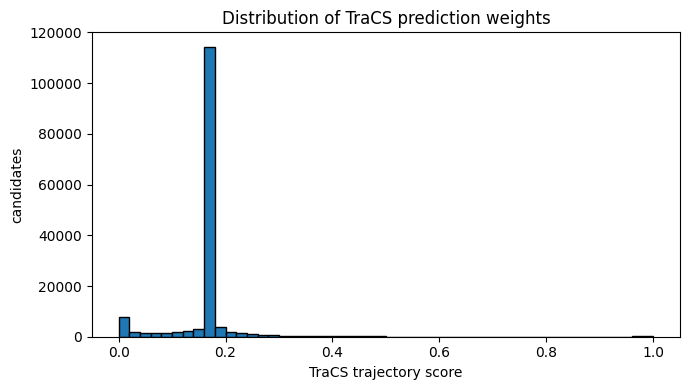

mean=0.1667  std=0.0916  min=0.0000  p25=0.1667  p50=0.1667  p75=0.1667  max=1.0000


In [10]:
tracs_scores = train_data["tracs_trajectory_score"].values

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores, bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights")
plt.tight_layout()
plt.show()

v = tracs_scores
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

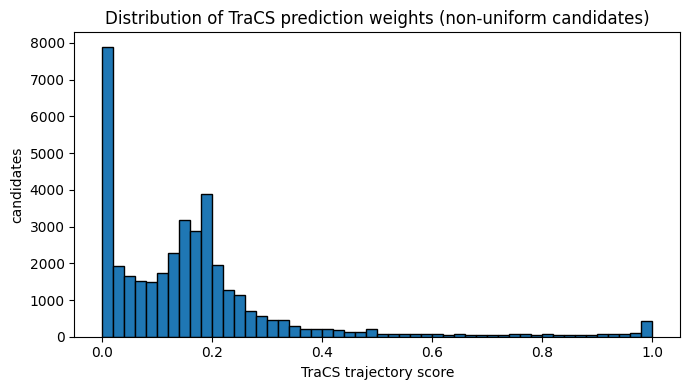

mean=0.1667  std=0.0916  min=0.0000  p25=0.1667  p50=0.1667  p75=0.1667  max=1.0000


In [11]:
tracs_scores_nonuniform = train_data["tracs_trajectory_score"].values.reshape(-1, 6)
tracs_scores_nonuniform = tracs_scores_nonuniform[tracs_scores_nonuniform.std(axis=1) > 0.01, :].flatten()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores_nonuniform, bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights (non-uniform candidates)")
plt.tight_layout()
plt.show()

v = tracs_scores
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

In [12]:
if not features_pt_path.exists() or not optimal_weights_pt_path.exists():
    all_features = []
    all_weights = []

    for scenario_id, scenario_data in tqdm.tqdm(train_data.groupby("scenario_id")):
        gt_row = val_gt.loc[scenario_id]
        gt_track = np.stack([
            np.array(gt_row["gt_trajectory_x"]),
            np.array(gt_row["gt_trajectory_y"])
        ], axis=1).astype(np.float64)

        log_tracs_scores = np.log(np.array(scenario_data["tracs_trajectory_score"]))
        log_backbone_scores = np.log(np.array(scenario_data["backbone_trajectory_score"]))
        predicted_tracks = np.moveaxis(
            np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
            source=[0, 1, 2], destination=[2, 0, 1],
        ).astype(np.float64)

        w1, w2, _, _, _ = optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track)

        all_features.append(FusionNet.extract_features(predicted_tracks))
        all_weights.append([w1, w2])

    F = torch.tensor(np.stack(all_features), dtype=torch.float32)
    W = torch.tensor(np.array(all_weights), dtype=torch.float32)
    print(f"Dataset: {F.shape} features, {W.shape} labels")

    torch.save(F, features_pt_path)
    torch.save(W, optimal_weights_pt_path)

In [13]:
F = torch.load(features_pt_path, weights_only=True)
W = torch.load(optimal_weights_pt_path, weights_only=True)

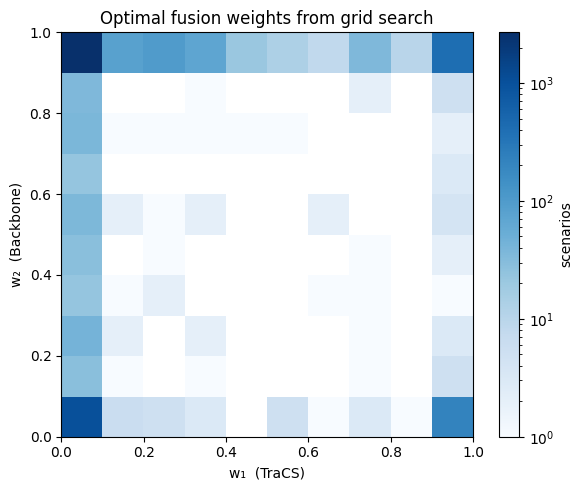

                      mean     std     min     p25     p50     p75     max
w₁  (TraCS)          0.155   0.340   0.000   0.000   0.000   0.000   1.000
w₂  (Backbone)       0.716   0.436   0.000   0.052   1.000   1.000   1.000


In [14]:
w_np = W.numpy()
counts, w1_edges, w2_edges = np.histogram2d(w_np[:, 0], w_np[:, 1], bins=10, range=[[0, 1], [0, 1]])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(counts.T, origin="lower", aspect="auto",
               extent=[w1_edges[0], w1_edges[-1], w2_edges[0], w2_edges[-1]],
               cmap="Blues", norm=plt.matplotlib.colors.LogNorm(vmin=counts[counts > 0].min(), vmax=counts.max()))
plt.colorbar(im, ax=ax, label="scenarios")
ax.set_xlabel("w₁  (TraCS)")
ax.set_ylabel("w₂  (Backbone)")
ax.set_title("Optimal fusion weights from grid search")
plt.tight_layout()
plt.show()

header = f"{'':18s}  {'mean':>6}  {'std':>6}  {'min':>6}  {'p25':>6}  {'p50':>6}  {'p75':>6}  {'max':>6}"
print(header)
for col, label in [(0, "w₁  (TraCS)"), (1, "w₂  (Backbone)")]:
    v = w_np[:, col]
    print(f"{label:18s}  {v.mean():6.3f}  {v.std():6.3f}  {v.min():6.3f}  "
          f"{np.percentile(v,25):6.3f}  {np.percentile(v,50):6.3f}  "
          f"{np.percentile(v,75):6.3f}  {v.max():6.3f}")

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
F, W = F.to(device), W.to(device)

n_epochs = 200
model = FusionNet(F.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

for epoch in range(n_epochs):
    for idx in torch.randperm(len(F)).split(256):
        optimizer.zero_grad()
        nn.functional.mse_loss(model(F[idx]), W[idx]).backward()
        optimizer.step()
    scheduler.step()
    if epoch % 20 == 0:
        with torch.no_grad():
            loss = nn.functional.mse_loss(model(F), W).item()
            w_pred = model(F).cpu().numpy()
            print(f"Epoch {epoch}: loss={loss:.4f}  mean w1={w_pred[:,0].mean():.2f}  mean w2={w_pred[:,1].mean():.2f}")

Epoch 0: loss=0.1678  mean w1=0.10  mean w2=0.81
Epoch 20: loss=0.1514  mean w1=0.15  mean w2=0.74
Epoch 40: loss=0.1494  mean w1=0.17  mean w2=0.68
Epoch 60: loss=0.1472  mean w1=0.15  mean w2=0.75
Epoch 80: loss=0.1456  mean w1=0.16  mean w2=0.73
Epoch 100: loss=0.1426  mean w1=0.18  mean w2=0.75
Epoch 120: loss=0.1382  mean w1=0.16  mean w2=0.69
Epoch 140: loss=0.1315  mean w1=0.15  mean w2=0.71
Epoch 160: loss=0.1277  mean w1=0.15  mean w2=0.71
Epoch 180: loss=0.1250  mean w1=0.15  mean w2=0.72


In [ ]:
test_data = pd.read_parquet(test_data_path)
ground_truth = pd.read_parquet(test_ground_truth_path)
backbone_scores = []
fusion_scores = []
agent_types = []

for scenario_id in tqdm.tqdm(test_data["scenario_id"].unique()):
    gt_row = ground_truth[ground_truth["scenario_id"] == scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"].iloc[0]),
        np.array(gt_row["gt_trajectory_y"].iloc[0])
    ], axis=1).astype(np.float64)

    scenario_data = test_data[test_data["scenario_id"] == scenario_id]
    backbone_probs = np.array(scenario_data["backbone_trajectory_score"], dtype=np.float64)
    tracs_scores = np.array(scenario_data["tracs_trajectory_score"], dtype=np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    agent_types.append(scenario_data["agent_type"].iloc[0])

    # Backbone only
    backbone_probs_norm = backbone_probs / backbone_probs.sum()
    backbone_scores.append(metrics.compute_brier_ade(predicted_tracks, gt_track, backbone_probs_norm).min())

    # FusionNet
    w1, w2 = model.predict_weights(predicted_tracks)
    log_fused = w1 * np.log(tracs_scores + 1e-10) + w2 * np.log(backbone_probs + 1e-10)
    fused_probs = np.exp(log_fused - log_fused.max())
    fused_probs /= fused_probs.sum()
    fusion_scores.append(metrics.compute_brier_ade(predicted_tracks, gt_track, fused_probs).min())

backbone_scores = np.array(backbone_scores)
fusion_scores = np.array(fusion_scores)
agent_types = np.array(agent_types)

print(f"Backbone   Brier-minADE: {backbone_scores.mean():.4f}")
print(f"FusionNet  Brier-minADE: {fusion_scores.mean():.4f}")
delta = fusion_scores - backbone_scores
print(f"Delta: {delta.mean():.4f}  ({(fusion_scores.mean() / backbone_scores.mean() - 1) * 100:.1f}%)")
balanced_delta = 0
for vtype in sorted(set(agent_types)):
    mask = agent_types == vtype
    balanced_delta += (fusion_scores[mask].mean() - backbone_scores[mask].mean())
balanced_delta /= len(set(agent_types))
balanced_backbone_scores = []  # TODO
print(f"Balanced Delta (avg of per-type deltas): {balanced_delta:.4f} ({(NEIN fusion_scores.mean() / backbone_scores.mean() - 1) * 100:.1f}%)")

# Per-scenario improvement distribution
print(f"\nImproved: {(delta < 0).mean()*100:.1f}%  Degraded: {(delta > 0).mean()*100:.1f}%")

print("\nPer vehicle type:")
for vtype in sorted(set(agent_types)):
    mask = agent_types == vtype
    b = backbone_scores[mask]
    f = fusion_scores[mask]
    d = f - b
    print(f"  {vtype:14s}  n={mask.sum():4d}  Backbone={b.mean():.4f}  FusionNet={f.mean():.4f}  "
          f"Delta={f.mean()-b.mean():+.4f} ({(f.mean()/b.mean()-1)*100:+.1f}%)  "
          f"Improved={(d < 0).mean()*100:.1f}%  Degraded={(d > 0).mean()*100:.1f}% "
          f"Delta(improved)={d[d < 0].mean():.4f} ({d[d < 0].mean()/(b[d < 0].mean())*100:.1f}%) "
          f"Delta(degraded)={d[d > 0].mean():.4f} ({d[d > 0].mean()/(b[d > 0].mean())*100:.1f}%)")

100%|██████████| 15497/15497 [01:46<00:00, 145.99it/s]

Backbone   Brier-minADE: 1.3166
FusionNet  Brier-minADE: 1.3211
Delta: 0.0045  (0.3%)
Balanced Delta (avg of per-type deltas): -0.0013

Improved: 33.9%  Degraded: 66.1%

Per vehicle type:
  bus             n= 534  Backbone=1.5288  FusionNet=1.5269  Delta=-0.0019 (-0.1%)  Improved=42.3%  Degraded=57.7% Delta(improved)=-0.0586 (-3.5%) Delta(degraded)=0.0397 (2.8%)
  cyclist         n= 214  Backbone=1.3658  FusionNet=1.3718  Delta=+0.0059 (+0.4%)  Improved=28.5%  Degraded=71.5% Delta(improved)=-0.0493 (-2.6%) Delta(degraded)=0.0279 (2.4%)
  motorcyclist    n=  73  Backbone=1.4333  FusionNet=1.4435  Delta=+0.0102 (+0.7%)  Improved=32.9%  Degraded=67.1% Delta(improved)=-0.0395 (-2.5%) Delta(degraded)=0.0346 (2.5%)
  pedestrian      n=1008  Backbone=1.0001  FusionNet=0.9725  Delta=-0.0276 (-2.8%)  Improved=45.9%  Degraded=54.1% Delta(improved)=-0.1461 (-13.9%) Delta(degraded)=0.0731 (7.7%)
  vehicle         n=13668  Backbone=1.3303  FusionNet=1.3373  Delta=+0.0070 (+0.5%)  Improved=32.8%  De

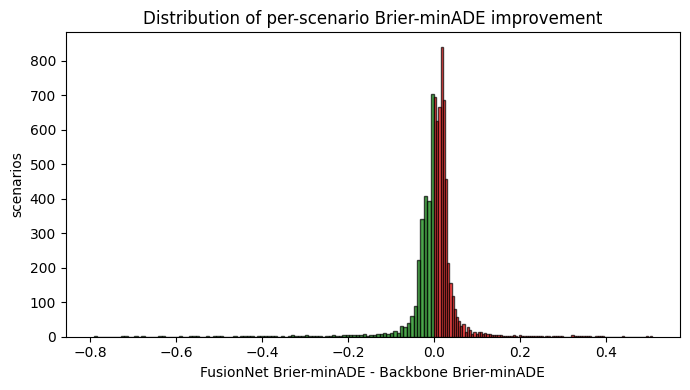

In [22]:
# Historgram of deltas
plt.figure(figsize=(7, 4))
plt.hist(delta[delta < 0], bins=100, edgecolor="black", color="green", alpha=0.7, label="Improved")
plt.hist(delta[delta > 0], bins=100, edgecolor="black", color="red", alpha=0.7, label="Degraded")
plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
plt.ylabel("scenarios")
plt.title("Distribution of per-scenario Brier-minADE improvement")
plt.tight_layout()
plt.show()

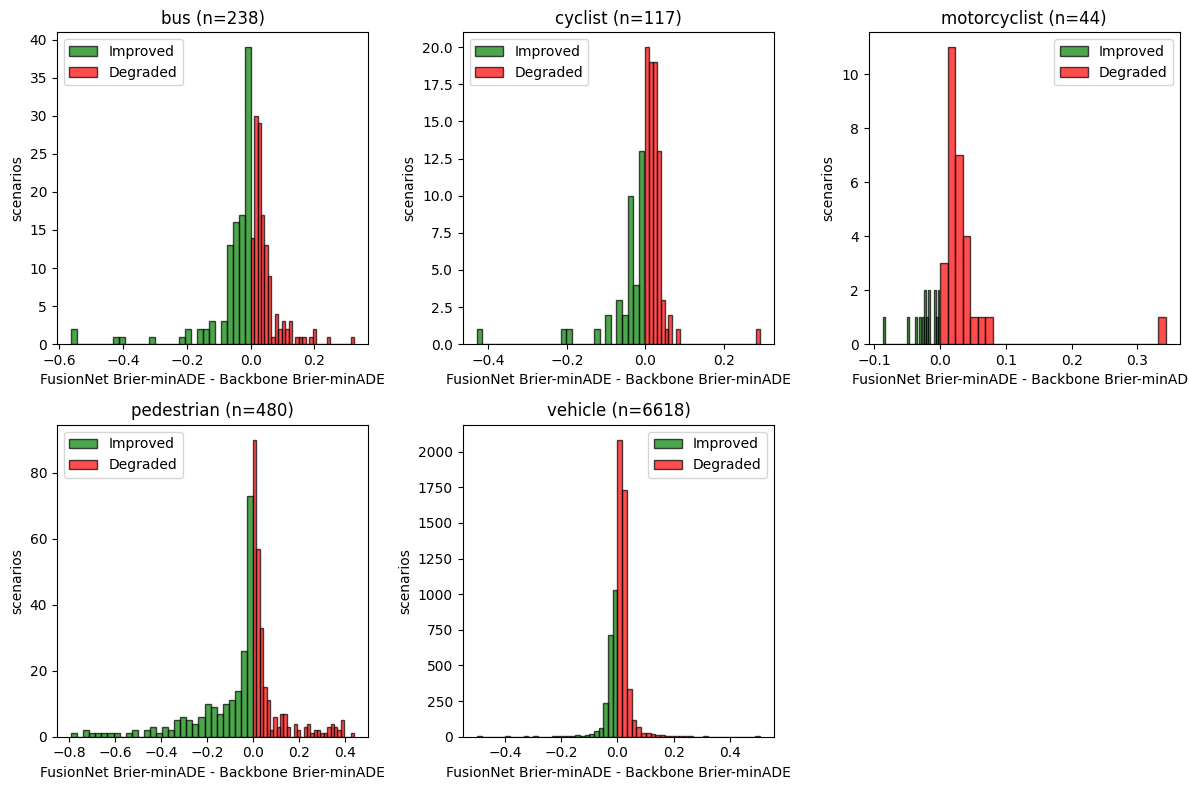

In [23]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    delta_v = delta[mask]
    plt.hist(delta_v[delta_v < 0], bins=30, edgecolor="black", color="green", alpha=0.7, label="Improved")
    plt.hist(delta_v[delta_v > 0], bins=30, edgecolor="black", color="red", alpha=0.7, label="Degraded")
    plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
    plt.legend()
plt.tight_layout()
plt.show()